# Age-Metallicity Relation (AMR) Analysis 

Here the Age-Metallicity Relation (AMR) for the cleaned catalogues of globular clusters found in Vandenberg (2013) & Krause (2016) will be outlined.

In [49]:
# Import libraries.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("globular_clusters_cleaned.csv")
fehlabel = "[Fe/H] (dex)"
agelabel = "Age (Gyr)"
data.head()

,FeH,Age,Age_err,Method,Figs,Range,HBtype,R_G,M_V,v_e0,...,r_h,mu_V,rho_0,lg_tc,lg_th,Mstar,rh,C5,Age_Krause,FeH_Krause
0,-0.76,11.75,0.25,V,14,11.50–11.75,-0.99,7.4,-9.42,54.8,...,3.17,14.38,4.88,7.84,9.55,6.46,7.10,0.92,12.80,-0.76
1,-1.32,11.50,0.38,H,24,NaN,0.98,12.0,-6.75,10.9,...,2.23,20.05,1.78,8.99,9.32,0.46,9.80,0.05,12.20,-1.32
2,-1.30,10.75,0.25,V,13,10.75–11.00,-0.87,9.4,-8.43,44.4,...,0.82,14.80,4.74,7.76,8.93,2.50,3.50,0.72,10.00,-1.26
3,-1.27,10.75,0.25,V,13,10.75–11.25,-0.71,18.1,-7.80,23.6,...,0.68,17.73,2.99,8.59,9.12,3.41,5.50,0.62,10.24,-1.08
4,-1.18,11.00,0.25,V,13,10.75–11.25,-0.32,16.6,-8.33,47.6,...,0.51,14.25,5.09,7.43,8.82,5.51,3.05,1.81,7.64,-1.13


In [50]:
# Check data is loaded correctly
data.head()
data.columns

Index(['FeH', 'Age', 'Age_err', 'Method', 'Figs', 'Range', 'HBtype', 'R_G',
       'M_V', 'v_e0', 'log_sigma_0', 'Cluster_ID', 'RA', 'DEC', 'L', 'B',
       'R_Sun', 'R_gc', 'X', 'Y', 'Z', 'v_r', 'v_r_e', 'v_LSR', 'sig_v',
       'sig_v_e', 'c', 'r_c', 'r_h', 'mu_V', 'rho_0', 'lg_tc', 'lg_th',
       'Mstar', 'rh', 'C5', 'Age_Krause', 'FeH_Krause'],
      dtype='str')

In [51]:
# Check for missing values in the age and metallicity columns of both datasets
data[["Cluster_ID", "FeH", "Age", "Age_err", "FeH_Krause", "Age_Krause"]].isna().sum()

Cluster_ID    0
FeH           0
Age           0
Age_err       0
FeH_Krause    3
Age_Krause    3
dtype: int64

Original data labelling guide for VandenBerg et al. (2013).
- Cluster_ID: Identifier of the globular cluster
- FeH: Metallicity, [Fe/H]
- Age: Absolute age (Gyr)
- Age_err: Uncertainty in the age (Gyr). This is only the isochrone-fitting error (approximately ±0.25 Gyr); VandenBerg et al. note that distance and chemical abundance uncertainties add a further factor of approximately ±1.5-2 Gyr.


Original data labelling guide for Krause et al. (2016).
- Age_Krause: Age (Gyr), compiled from data sets.
- FeH_Krause: Metallicity, [Fe/H] 


In [52]:
# Confirm the total number of clusters in each dataset.
print(data["Cluster_ID"].nunique())                    # VandenBerg
print(data["Age_Krause"].notna().sum())                # Krause

# Clusters in VandenBerg that are missing from Krause
print(data.loc[data["Age_Krause"].isna(), "Cluster_ID"])

55
52
7     NGC4147
52       Arp2
54    Terzan8
Name: Cluster_ID, dtype: str


## Fitting the Age-Metallicity Relation

A line of best fit, Age = a [Fe/H] + b, is calculated and depicted for the two graph. The fit is repeated, each time leaving out clusters more than 3σ from the line, so that extreme clusters do not pull the fit. The VandenBerg fit is weighted by 1/Age_err (note these errors are fitting errors only, so the weights reflect relative, not total, uncertainty). Krause possesses no given age uncertainty hence the plot displayed possesses an unweighted fit.

Clusters whose residual from the final line is greater than 2σ are taken as outliers.

In [ ]:
# Implement astronomical figures from cleaned catalogue for globular clusters (FeH,Age, Age_err)                          
FeH, Age, Age_err = data["FeH"], data["Age"], data["Age_err"]
# Create a new DataFrame for Krause data, dropping rows with missing values in Age_Krause and FeH_Krause
krause = data.dropna(subset=["Age_Krause", "FeH_Krause"]).copy()

# Define a function to fit the Age-Metallicity Relation (AMR) using weighted linear regression with iterative sigma clipping.

def fit_amr(x, y, yerr=None, clip=3, niter=10):
    x, y = np.asarray(x), np.asarray(y)
    w = np.ones_like(x) if yerr is None else 1 / np.asarray(yerr)
    keep = np.ones_like(x, dtype=bool)
    for _ in range(niter):
        a, b = np.polyfit(x[keep], y[keep], 1, w=w[keep])
        resid = y - (a * x + b)
        sigma = np.std(resid[keep], ddof=2)
        new_keep = np.abs(resid) < clip * sigma
        if np.array_equal(new_keep, keep):
            break
        keep = new_keep
    return a, b, sigma, resid

# Fit the AMR for both datasets and store the results in the DataFrame.

aV, bV, sigmaV, residV = fit_amr(FeH, Age, Age_err)
data["residV"] = residV
print(f"VandenBerg: Age = {aV:.2f} [Fe/H] + {bV:.2f}, scatter = {sigmaV:.2f} Gyr")

aK, bK, sigmaK, residK = fit_amr(krause["FeH_Krause"], krause["Age_Krause"])
krause["residK"] = residK
print(f"Krause: Age = {aK:.2f} [Fe/H] + {bK:.2f}, scatter = {sigmaK:.2f} Gyr")

VandenBerg: Age = -0.92 [Fe/H] + 10.54, scatter = 0.48 Gyr
Krause: Age = -0.54 [Fe/H] + 11.75, scatter = 1.02 Gyr


In [ ]:
# Identify outliers based on residuals exceeding 2 times the standard deviation for both datasets.
out1 = data[np.abs(data["residV"]) > 2 * sigmaV]
out2 = krause[np.abs(krause["residK"]) > 2 * sigmaK]
print(out1[["Cluster_ID", "FeH", "Age", "residV"]])
print(out2[["Cluster_ID", "FeH_Krause", "Age_Krause", "residK"]])

   Cluster_ID   FeH    Age    residV
2      NGC362 -1.30  10.75 -0.993203
3     NGC1261 -1.27  10.75 -0.965497
23    NGC6218 -1.33  13.00  1.229091
28    NGC6362 -1.07  12.50  0.969208
53      Pal12 -0.81   9.00 -2.290674
   Cluster_ID  FeH_Krause  Age_Krause    residK
2      NGC362       -1.26       10.00 -2.430529
3     NGC1261       -1.08       10.24 -2.092629
4     NGC1851       -1.13        7.64 -4.719824
32    NGC6535       -1.51       10.50 -2.066502
53      Pal12       -0.81        8.60 -3.585779


## Plot 1: VandenBerg et al. (2013)

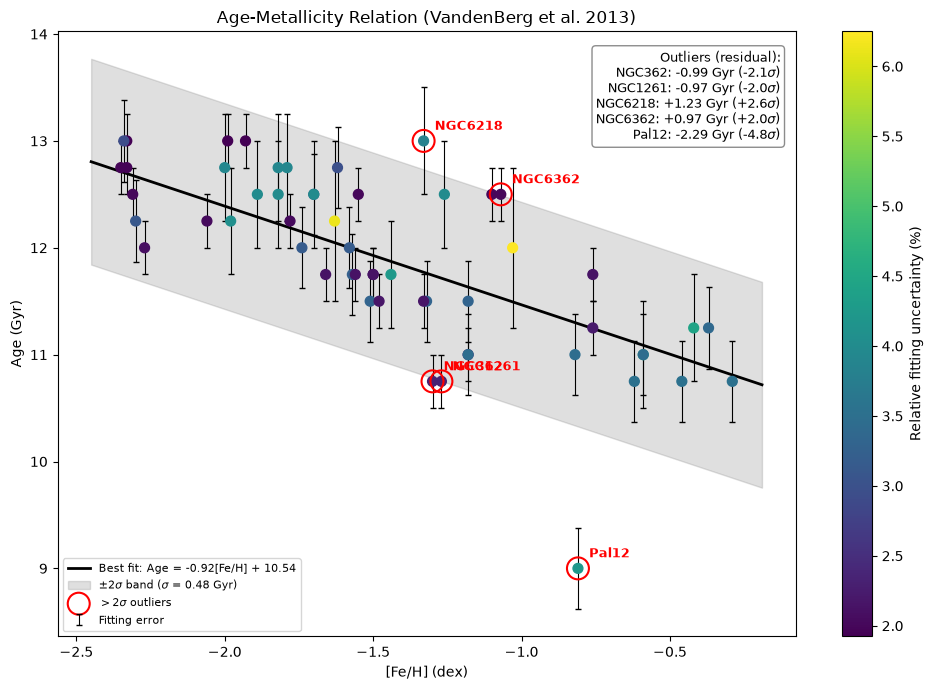

Outliers: NGC362, NGC1261, NGC6218, NGC6362, Pal12


In [ ]:
# Create a scatter plot of the Age-Metallicity Relation (AMR) with error bars, best-fit line, and outliers highlighted.
import re
import numpy as np
import matplotlib.pyplot as plt

# Define a function to find the correct column name in the DataFrame, ignoring case and special characters.
def find_col(df, target):
    norm = lambda s: re.sub(r"[^a-z0-9]", "", s.lower())
    for c in df.columns:
        if norm(c) == norm(target):
            return c
    raise KeyError(f"{target} not found in {list(df.columns)}")

age_col   = find_col(data, "Age")
err_col   = find_col(data, "Ageerr")
feh_col   = find_col(data, "FeH")
id_col    = find_col(data, "ClusterID")
resid_col = find_col(out1, "residV")

# Calculate relative error for colour mapping in the scatter plot.
data["RelErr"] = data[err_col] / data[age_col]

# Prepare data for plotting the best-fit line and the ±2σ band.
x = data[feh_col].values
y = data[age_col].values
xfit = np.linspace(x.min() - 0.1, x.max() + 0.1, 100)
yfit = aV * xfit + bV

# Create the scatter plot with error bars, best-fit line, ±2σ band, and outliers highlighted.
fig, ax = plt.subplots(figsize=(10, 7))

sc = ax.scatter(x, y, c=data["RelErr"] * 100, cmap="viridis", s=50, zorder=3)
ax.errorbar(x, y, yerr=data[err_col], fmt="none", ecolor="k",
            elinewidth=0.8, capsize=2, label="Fitting error", zorder=2)
fig.colorbar(sc, ax=ax, label="Relative fitting uncertainty (%)")

ax.plot(xfit, yfit, "k-", lw=2, label=f"Best fit: Age = {aV:.2f}[Fe/H] + {bV:.2f}")
ax.fill_between(xfit, yfit - 2*sigmaV, yfit + 2*sigmaV, color="grey", alpha=0.25,
                label=rf"$\pm2\sigma$ band ($\sigma$ = {sigmaV:.2f} Gyr)")

ax.scatter(out1[feh_col], out1[age_col], s=250, facecolors="none",
           edgecolors="r", linewidths=1.5, label=r"$>2\sigma$ outliers", zorder=4)
for _, r in out1.iterrows():
    ax.annotate(r[id_col], (r[feh_col], r[age_col]), xytext=(8, 8),
                textcoords="offset points", fontsize=9, weight="bold", color="r")

lines = ["Outliers (residual):"] + [
    f"{r[id_col]}: {r[resid_col]:+.2f} Gyr ({r[resid_col]/sigmaV:+.1f}$\\sigma$)"
    for _, r in out1.iterrows()
]
ax.text(0.98, 0.97, "\n".join(lines), transform=ax.transAxes, ha="right", va="top",
        fontsize=9, bbox=dict(boxstyle="round", fc="white", ec="grey", alpha=0.9))

# Set axis labels, title, legend, and save the figure.
ax.set_xlabel("[Fe/H] (dex)")
ax.set_ylabel("Age (Gyr)")
ax.set_title("Age-Metallicity Relation (VandenBerg et al. 2013)")
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig("amr_fit_no_systematics.png", dpi=200)
plt.show()

print("Outliers:", ", ".join(out1[id_col]))

In [ ]:
# Print out outliers for reference (easier to copy from notebook over figure). 
print("VandenBerg outliers:", ", ".join(out1["Cluster_ID"]))

VandenBerg outliers: NGC362, NGC1261, NGC6218, NGC6362, Pal12


## Plot 2: Krause et al. (2016)

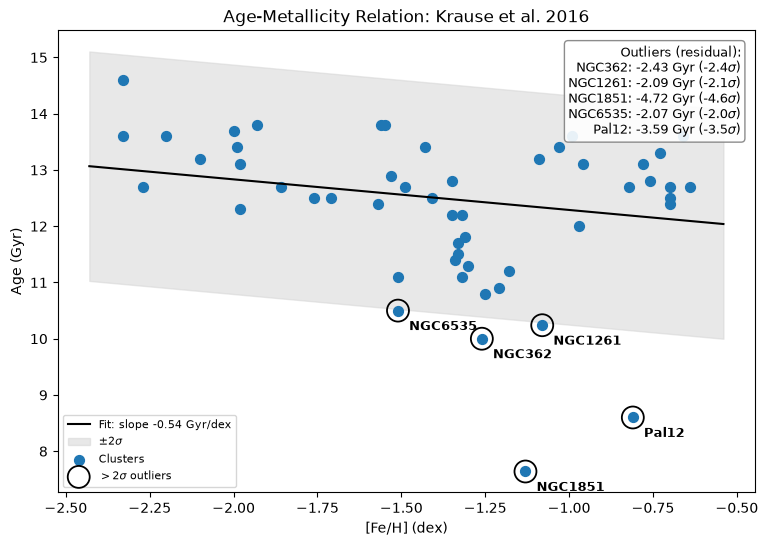

In [ ]:
# Create a scatter plot of the Age-Metallicity Relation (AMR) with error bars, best-fit line, and outliers highlighted for Krause et al. 2016 data.
plt.figure(figsize=(9, 6))
xfit = np.linspace(krause["FeH_Krause"].min() - 0.1, krause["FeH_Krause"].max() + 0.1, 100)
plt.plot(xfit, aK * xfit + bK, "k-", label=f"Fit: slope {aK:.2f} Gyr/dex")
plt.fill_between(xfit, aK * xfit + bK - 2 * sigmaK, aK * xfit + bK + 2 * sigmaK,
                 color="lightgrey", alpha=0.5, label=r"$\pm 2\sigma$")
plt.scatter(krause["FeH_Krause"], krause["Age_Krause"], color="tab:blue", s=50, label="Clusters")
plt.scatter(out2["FeH_Krause"], out2["Age_Krause"], s=250, facecolors="none",
            edgecolors="k", linewidths=1.3, label=r"$>2\sigma$ outliers")
for _, r in out2.iterrows():
    plt.annotate(r["Cluster_ID"], (r["FeH_Krause"], r["Age_Krause"]),
                 xytext=(8, -14 if r["residK"] < 0 else 8),
                 textcoords="offset points", fontsize=9, weight="bold")

# Include outliers in graph (as its just a general improvement)
lines = ["Outliers (residual):"] + [
    f"{r['Cluster_ID']}: {r['residK']:+.2f} Gyr ({r['residK']/sigmaK:+.1f}$\\sigma$)"
    for _, r in out2.iterrows()
]
plt.gca().text(0.98, 0.97, "\n".join(lines), transform=plt.gca().transAxes,
               ha="right", va="top", fontsize=9,
               bbox=dict(boxstyle="round", fc="white", ec="grey", alpha=0.9))

# Set axis labels, title, legend, and save the figure.

plt.xlabel(fehlabel); plt.ylabel(agelabel)
plt.title("Age-Metallicity Relation: Krause et al. 2016")
plt.legend(fontsize=8, loc="lower left")
plt.savefig("amr_krause_outliers.png", dpi=200)
plt.show()

In [58]:
# Print out outliers for reference (easier to copy from notebook over figure). 
print("Krause outliers:", ", ".join(out2["Cluster_ID"]))

Krause outliers: NGC362, NGC1261, NGC1851, NGC6535, Pal12


## Plot 3: Vandenberg, Relative Age Uncertainty versus Fe/H coloured by Age 

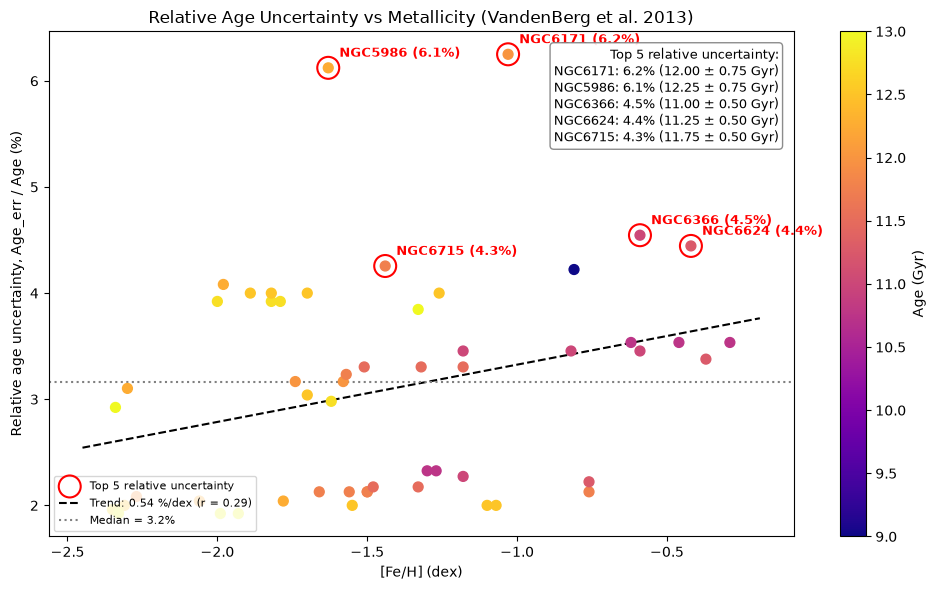

Highest relative uncertainty: NGC6171, NGC5986, NGC6366, NGC6624, NGC6715


In [147]:
# Calculate relative age uncertainty (as a percentage))
rel_pct = data[err_col] / data[age_col] * 100
data["RelErr_pct"] = rel_pct

# Highlight the clusters with the highest relative uncertainty (top 5) in the scatter plot.
N_TOP = 5
top_idx = rel_pct.nlargest(N_TOP).index
# Alternative: top_idx = rel_pct[rel_pct >= rel_pct.quantile(0.90)].index
is_top = data.index.isin(top_idx)

fig, ax = plt.subplots(figsize=(10, 6))

# All clusters, coloured by age
sc = ax.scatter(data[feh_col], rel_pct, c=data[age_col], cmap="plasma", s=50, zorder=3)
fig.colorbar(sc, ax=ax, label="Age (Gyr)")

# Highlight the highest-uncertainty clusters with red rings 
ax.scatter(data.loc[is_top, feh_col], rel_pct[is_top], s=250, facecolors="none",
           edgecolors="r", linewidths=1.5, zorder=4,
           label=f"Top {N_TOP} relative uncertainty")
for _, r in data[is_top].iterrows():
    ax.annotate(f"{r[id_col]} ({r['RelErr_pct']:.1f}%)", (r[feh_col], r["RelErr_pct"]),
                xytext=(8, 8), textcoords="offset points",
                fontsize=9, weight="bold", color="r")

# Linear trend with correlation coefficient
m, c = np.polyfit(data[feh_col], rel_pct, 1)
xs = np.linspace(data[feh_col].min() - 0.1, data[feh_col].max() + 0.1, 100)
rho = np.corrcoef(data[feh_col], rel_pct)[0, 1]
ax.plot(xs, m * xs + c, "k--", lw=1.5, label=f"Trend: {m:.2f} %/dex (r = {rho:.2f})")

# Median reference line
med = rel_pct.median()
ax.axhline(med, color="grey", ls=":", label=f"Median = {med:.1f}%")

# Boxed list of the highest-uncertainty clusters
top = data[is_top].sort_values("RelErr_pct", ascending=False)
lines = [f"Top {N_TOP} relative uncertainty:"] + [
    f"{r[id_col]}: {r['RelErr_pct']:.1f}% ({r[age_col]:.2f} ± {r[err_col]:.2f} Gyr)"
    for _, r in top.iterrows()
]
ax.text(0.98, 0.97, "\n".join(lines), transform=ax.transAxes, ha="right", va="top",
        fontsize=9, bbox=dict(boxstyle="round", fc="white", ec="grey", alpha=0.9))

# Set axis labels, title, legend, and save the figure.
ax.set_xlabel("[Fe/H] (dex)")
ax.set_ylabel("Relative age uncertainty, Age_err / Age (%)")
ax.set_title("Relative Age Uncertainty vs Metallicity coloured by Age (VandenBerg et al. 2013)")
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig("relerr_vs_feh_top.png", dpi=200)
plt.show()

# Print out the clusters with the highest relative uncertainty for reference (easier to copy from notebook over figure).
print("Highest relative uncertainty:", ", ".join(top[id_col]))